# Projet Deep learning - CNN pour panneaux de signalisation

## Partie 1 - Présentation et traitement du dataset.

### Description du Dataset
Pour ce projet, nous allons utiliser le dataset GTSRB -German Traffics Signs Recognition Benchmark-. Voici ses informations :
- Auteur : Mykola
- License : CC0: Public Domain
- Taille dataset entrainement : 39209 images de panneaux (dans le répertoire d'entrainement)
- Taille dataset Test : 12630 images
- Nombre de classes: 43

### Description classes
Voici les différentes classes et leurs signification, ainsi que la quantité d'images par classe :


In [2]:
from pathlib import Path
import pandas as pd
import trafficsigns.data.observe_dataset as obs
from trafficsigns.config import ROOT

correspondance = {
    0: "Limite de vitesse (20 km/h)",
    1: "Limite de vitesse (30 km/h)",
    2: "Limite de vitesse (50 km/h)",
    3: "Limite de vitesse (60 km/h)",
    4: "Limite de vitesse (70 km/h)",
    5: "Limite de vitesse (80 km/h)",
    6: "Fin de limitation de vitesse (80 km/h)",
    7: "Limite de vitesse (100 km/h)",
    8: "Limite de vitesse (120 km/h)",
    9: "Interdiction de dépasser",
    10: "Interdiction de dépasser pour les véhicules > 3.5 t",
    11: "Interdiction d'intersection / Priorité à la prochaine intersection",
    12: "Route prioritaire",
    13: "Cédez le passage",
    14: "Stop",
    15: "Circulation interdite à tout véhicule dans les deux sens",
    16: "Interdiction d'accès aux véhicules > 3.5 t",
    17: "Sens interdit",
    18: "Danger",
    19: "Virage à gauche",
    20: "Virage à droite",
    21: "Successions de virages",
    22: "Casserole / Route bosselée",
    23: "Chaussée glissante",
    24: "Rétrécissement de la chaussée par la droite",
    25: "Travaux en cours",
    26: "Signaux lumineux / Feux tricolores",
    27: "Passage de piétons",
    28: "Attention enfants",
    29: "Passage de cyclistes",
    30: "Danger neige / verglas",
    31: "Passage d'animaux sauvages",
    32: "Fin de toutes les interdictions précédemment signalées",
    33: "Obligation de tourner à droite",
    34: "Obligation de tourner à gauche",
    35: "Obligation d'aller tout droit",
    36: "Obligation d'aller tout droit ou à droite",
    37: "Obligation d'aller tout droit ou à gauche",
    38: "Contournement obligatoire par la droite",
    39: "Contournement obligatoire par la gauche",
    40: "Rond-point",
    41: "Fin d'interdiction de dépasser",
    42: "Fin d'interdiction de dépasser pour les véhicules > 3.5 t",
}

print("== Quantités de chaque classe du dataset d'entrainement ==")

PATH_TO_FILES = Path.joinpath(ROOT, "data", "raw", "gtsrb")

data_frame = pd.read_csv(filepath_or_buffer=Path.joinpath(PATH_TO_FILES, "Train.csv"))

quantity_frame = obs.get_quantity_of_class(data_frame, "ClassId")

# 1. Mappage des IDs vers les libellés des panneaux
quantity_frame["Panneau"] = quantity_frame["ClassID"].map(correspondance)

# 2. Réorganisation des colonnes pour placer le libellé à côté de l'ID
quantity_frame = quantity_frame[["ClassID", "Panneau", "Quantité"]]

print(quantity_frame)
print(f"Nombre de classes : {len(quantity_frame)}")

== Quantités de chaque classe du dataset d'entrainement ==
    ClassID                                            Panneau  Quantité
0        20                                    Virage à droite       360
1         0                        Limite de vitesse (20 km/h)       210
2         1                        Limite de vitesse (30 km/h)      2220
3         2                        Limite de vitesse (50 km/h)      2250
4         3                        Limite de vitesse (60 km/h)      1410
5         4                        Limite de vitesse (70 km/h)      1980
6         5                        Limite de vitesse (80 km/h)      1860
7         6             Fin de limitation de vitesse (80 km/h)       420
8         7                       Limite de vitesse (100 km/h)      1440
9         8                       Limite de vitesse (120 km/h)      1410
10        9                           Interdiction de dépasser      1470
11       10  Interdiction de dépasser pour les véhicules > ...   

## Dimension des images

Les images ne sont pas toutes de la même taille. La taille s'étend de (25,25)px à (225,243)px avec une médiane de 43px. Nous avons décidé de prendre la puissance de 2 la plus proche de la médiane, c'est-à-dire (32,32)px.

== Informations sur la taille des images ==
         Hauteur  Largeur
Minimum     25.0     25.0
Median      43.0     43.0
Maximum    225.0    243.0


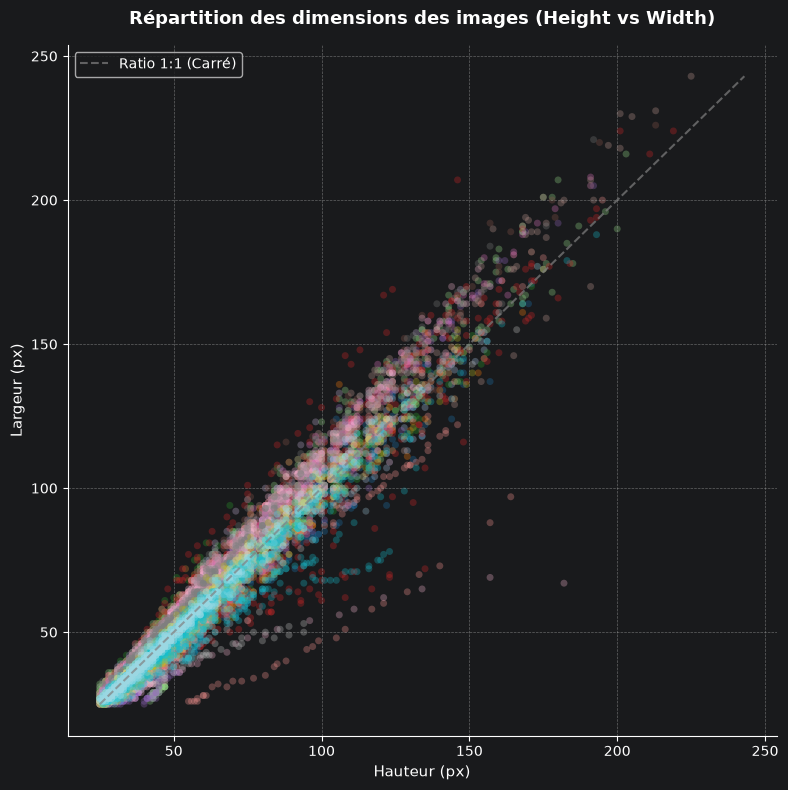

In [3]:
import numpy as np
print("== Informations sur la taille des images ==")

size_dataframe = pd.DataFrame({"Hauteur" : [data_frame['Height'].min(), np.median(np.array(data_frame['Height'])), data_frame['Height'].max()], "Largeur" : [data_frame['Width'].min(), np.median(np.array(data_frame['Width'])), data_frame['Width'].max()]}, index=["Minimum", "Median", "Maximum"])
print(size_dataframe)

obs.get_size_of_images_plot(data_frame)


## Format des images

- ".png" seulement
- 3 channels (RGB)
- 24 bits de profondeur

Toutes les images on exactement le même format, ce qui permet de les charger plus rapidement et de les traiter plus efficacement. (évite la création d'une classe de conversion de format)

# Déséquilibre des classes

Le dataset GTSRB est désiquilibré : des panneaux n'on que 200 exemples alors que d'autres en ont plus de 2000. Cela peut entraîner un surapprentissage des panneaux les plus fréquents et une sous-représentation des panneaux moins fréquents. Il est donc important de prendre en compte cette déséquilibre lors de l'entraînement du modèle.

Déséquilibre des classes
- Ratio entre la classe 2 et la classe 0:  10.71:1


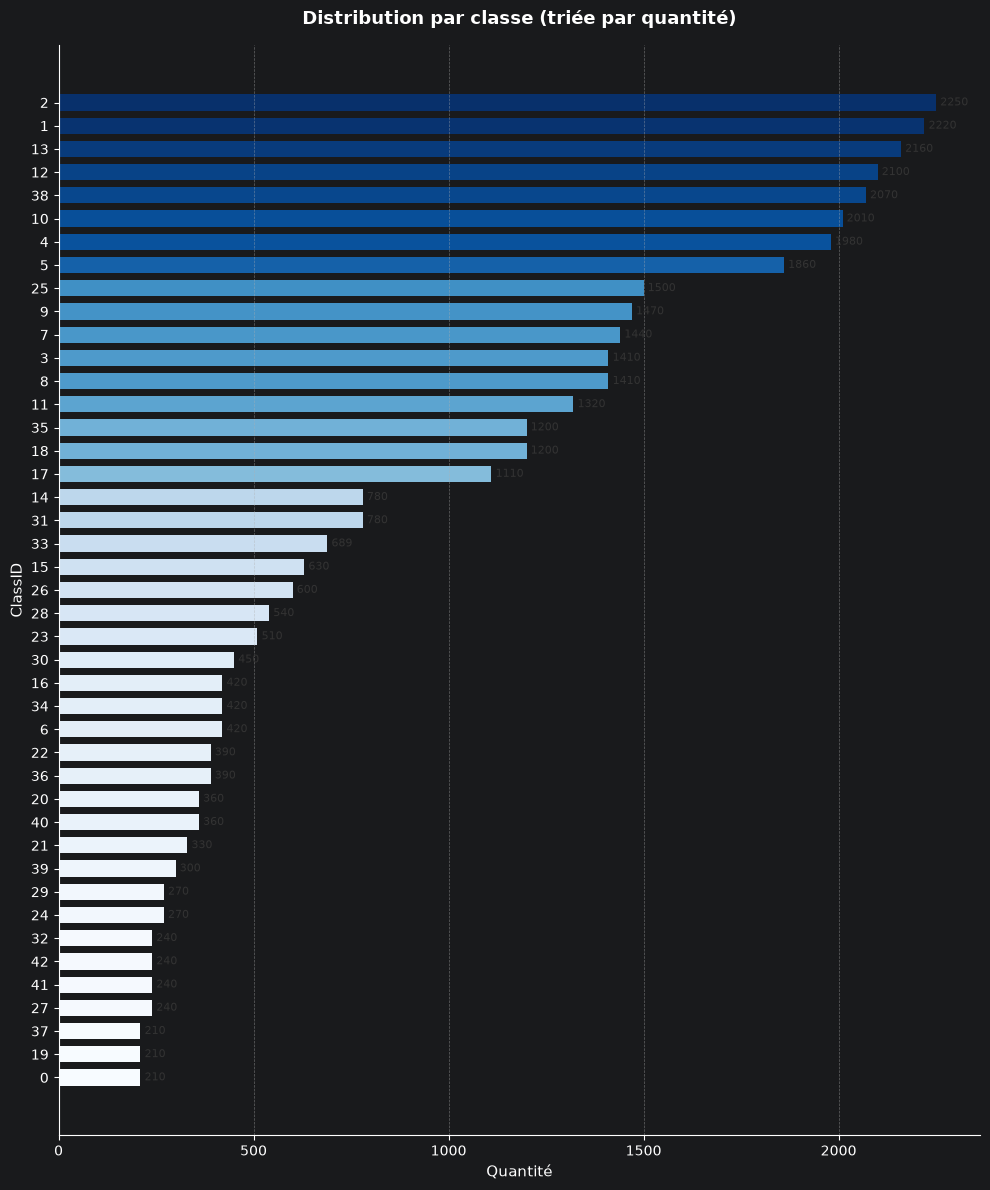

In [4]:
biggest_class = quantity_frame[quantity_frame['Quantité'].max() == quantity_frame['Quantité']]
smallest_class = quantity_frame[quantity_frame['Quantité'].min() == quantity_frame['Quantité']]

ratio = biggest_class['Quantité'].unique()[0]/smallest_class['Quantité'].unique()[0]

print("="*50)
print("Déséquilibre des classes")
print(f"- Ratio entre la classe {biggest_class['ClassID'].unique()[0]} et la classe {smallest_class['ClassID'].unique()[0]}:  {ratio:.2f}:1")
obs.get_size_plot(quantity_frame)

# Planche d'aperçus

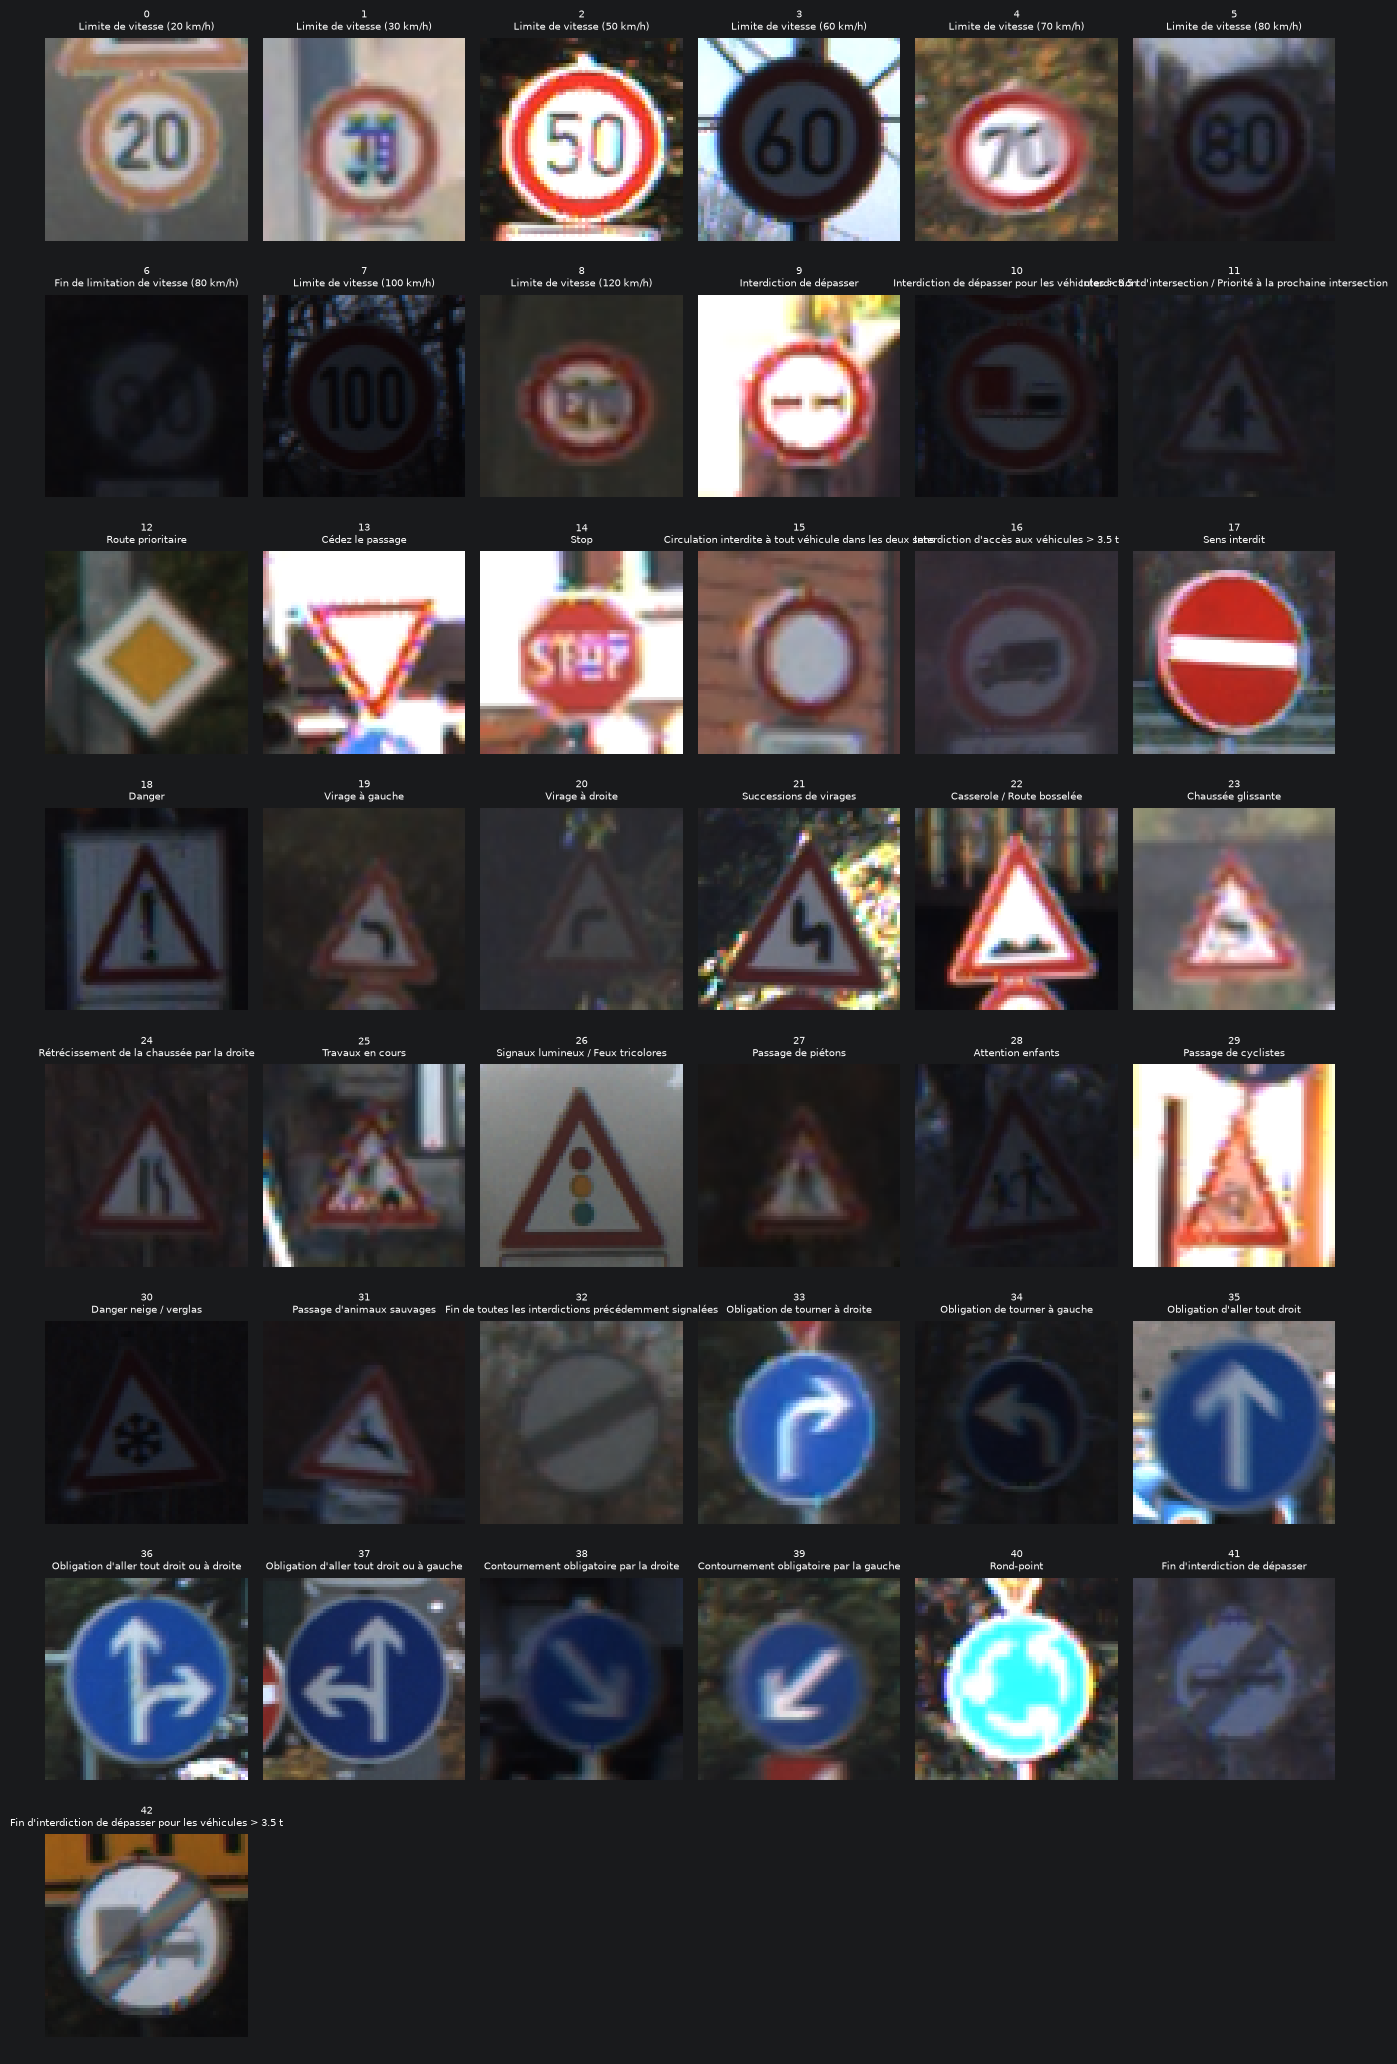

In [7]:
# Planche d'aperçu globale
obs.create_frame(ROOT / "data/raw/gtsrb/Train", correspondance, save_path=ROOT / "reports/figures/planche_classes.png")

# Planche d'aperçus détaillées
#obs.create_every_class_frame(ROOT / "data/raw/gtsrb/Train", correspondance, save_dir=ROOT / "reports/figures/detailed_classes")

# Préparation des données
## Chemin normal

Conversion des images => redimensionnement des images => Conversion en tenseur => Sauvegarde des données

In [ ]:
from trafficsigns.config import ROOT
from trafficsigns.data.preprocessing import build_dataset, save_dataset
from pathlib import Path
from trafficsigns.config import load_config

cfg = load_config(ROOT / "configs" / "base.yaml")

raw_dir = ROOT / cfg["data"]["raw_dir"]
output_dir = ROOT / cfg["data"]["processed_dir"]
# Dataset classique
img_X, img_y, img_paths = build_dataset(raw_dir)
save_dataset(img_X, img_y, img_paths, Path.joinpath(output_dir, "train"))


## Séparation des données

20 % de validation, 80 % d'entrainement

In [ ]:
# split des valeurs

from trafficsigns.config import load_config
from trafficsigns.data.dataset import load_dataset
from trafficsigns.data.split import grouped_stratified_split, assert_no_leakage, save_split, val_fraction_per_class, extract_group_keys
from trafficsigns.config import ROOT
import numpy as np

cfg_path = Path.joinpath(ROOT, "configs", "base.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}
loaded_seed = cfg["seed"]
loaded_val_ratio = cfg["split"]["val_ratio"]

processed = Path.joinpath(ROOT, cfg["data"]["processed_dir"])
_, new_y, paths = load_dataset(processed, mmap=True)
new_groups = extract_group_keys(paths)

new_train_idx, new_val_idx = grouped_stratified_split(new_y, new_groups, loaded_val_ratio, loaded_seed)
assert_no_leakage(new_groups, new_train_idx, new_val_idx)
save_split(new_train_idx, new_val_idx, processed, loaded_seed, loaded_val_ratio)

print(f"train : {len(new_train_idx)} images, {len(np.unique(new_groups[new_train_idx]))} panneaux")
print(f"val   : {len(new_val_idx)} images, {len(np.unique(new_groups[new_val_idx]))} panneaux "
          f"({len(new_val_idx) / len(new_y):.1%})")
frac = val_fraction_per_class(new_y, new_val_idx)
print(f"part de validation par classe : min {frac.min():.1%}, max {frac.max():.1%}")

Le dataset GTSRB est déjà découpé en train et test. Ainsi, on ne fait que le découpage entre Train et Validation. Dans ces scripts, on s'assure qu'iil n'y a pas de fuites de données entre l'entrainement et la validation (à cause des séquences d'images).

# Le modèle Baseline

Le modèle "baseline" est un réseau de neurones classique.

In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs", "base.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

In [ ]:
# évaluation du modèle
from trafficsigns.config import ROOT, load_config
from trafficsigns.evaluation.metrics import evaluate_model
from pathlib import Path

cfg = load_config(Path(ROOT) / "configs" / "base.yaml")

raw_dir = ROOT / cfg["data"]["raw_dir"]
evaluate_model(
    model_path=ROOT / cfg["model"]["dir"] / "model.keras",
    test_csv=raw_dir / cfg["data"]["test_csv"],
    img_dir=raw_dir,
    train_dir=ROOT / cfg["data"]["processed_dir"],
    out_dir=ROOT / cfg["reports"]["result_dir"] / cfg["model"]["name"],
)

# CNN

le CNN est une version amélioré du réseau de neurones classique. Il utilise des filtres convolutifs pour extraire des caractéristiques des images.

In [ ]:
# Création du modèle selon la configuration du fichier du CNN
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs", "base_cnn.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

In [ ]:
# évaluation du modèle
from trafficsigns.config import ROOT, load_config
from trafficsigns.evaluation.metrics import evaluate_model
from pathlib import Path

cfg = load_config(Path(ROOT) / "configs" / "base_cnn.yaml")

raw_dir = ROOT / cfg["data"]["raw_dir"]
evaluate_model(
    model_path=ROOT / cfg["model"]["dir"] / "model.keras",
    test_csv=raw_dir / cfg["data"]["test_csv"],
    img_dir=raw_dir,
    train_dir=ROOT / cfg["data"]["processed_dir"],
    out_dir=ROOT / cfg["reports"]["result_dir"] / cfg["model"]["name"],
)

# Expériences

Différentes expériences ont été effectuées pour améliorer les performances du modèle. Les principales expériences incluent l'utilisation de différentes architectures de réseaux de neurones, l'ajout de couches de régularisation, l'ajustement des hyperparamètres et l'expérimentation avec des techniques d'augmentation de données.

## 1. Data augmentation

Le principe : équilibré les classes d'images pour éviter le sur ajustement du modèle. Pour cela, un nouveau préprocessing est nécessaire.

In [ ]:
# Nouveau préprocessing
from trafficsigns.config import ROOT, load_config
from trafficsigns.data.data_augmentation import balance_and_augment_dataset
from trafficsigns.data.preprocessing import build_dataset, save_dataset
from pathlib import Path

cfg = load_config(Path(ROOT) / "configs" / "exp_configs" / "db_aug.yaml")

# Creation par data augmentation
# 1. Chargement/Build brut
X, y, paths = build_dataset(raw_dir)
print(f"Dataset brut : {X.shape[0]} images au total.")

# 2. Augmentation & Rééquilibrage (ex: 2000 images par classe = 86 000 images)
X_aug, y_aug, paths_aug = balance_and_augment_dataset(X, y, paths, target_per_class=2000)

# 3. Sauvegarde dans le dossier processed/train sous forme .npy
save_dataset(X_aug, y_aug, paths_aug, Path.joinpath(output_dir, "train_augmented"))
print(f"Dataset augmenté sauvegardé sous '{output_dir}'.")
print(f"x_augmented shape: {X_aug.shape}")
print(f"y_augmented shape: {y_aug.shape}")

In [ ]:
# split des valeurs

from trafficsigns.config import load_config
from trafficsigns.data.dataset import load_dataset
from trafficsigns.data.split import grouped_stratified_split, assert_no_leakage, save_split, val_fraction_per_class, extract_group_keys
from trafficsigns.config import ROOT
import numpy as np

cfg_path = Path.joinpath(ROOT, "configs", "exp_configs", "db_aug.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}
loaded_seed = cfg["seed"]
loaded_val_ratio = cfg["split"]["val_ratio"]

processed = Path.joinpath(ROOT, cfg["data"]["processed_dir"])
_, new_y, paths = load_dataset(processed, mmap=True)
new_groups = extract_group_keys(paths)

new_train_idx, new_val_idx = grouped_stratified_split(new_y, new_groups, loaded_val_ratio, loaded_seed)
assert_no_leakage(new_groups, new_train_idx, new_val_idx)
save_split(new_train_idx, new_val_idx, processed, loaded_seed, loaded_val_ratio)

print(f"train : {len(new_train_idx)} images, {len(np.unique(new_groups[new_train_idx]))} panneaux")
print(f"val   : {len(new_val_idx)} images, {len(np.unique(new_groups[new_val_idx]))} panneaux "
          f"({len(new_val_idx) / len(new_y):.1%})")
frac = val_fraction_per_class(new_y, new_val_idx)
print(f"part de validation par classe : min {frac.min():.1%}, max {frac.max():.1%}")

In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"db_aug.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

## 2. Changement de taille de batch

On décide de changer la taille de batch pour voir si cela améliore les performances du modèle. On passe de 32 à 8 images. 

In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"cfg_batch.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

## 3. Changement de modèle

On change les paramètres du CNN : 


In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"base_cnn.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

print(data_cfg.get("processed_dir", "data/processed/train"))
train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)